# Fraunhofer alphabet

The aim here is to reproduce an activity published as _Fraunhofer Alphabet_ Alan Winter 1980 _Phys. Educ._ *15* 291; using more modern looking diffraction patterns simulated in python using code written to accompany the text Adams, C.S. & Hughes, I.G. _Optics f2f: From Fourier to Fresnel_, OUP (2018)

The general idea of the activity is to use the examples of diffraction patterns produced by apertures in the familiar shapes of capital letters to increase familiarity and insight with the properties of Fourier transforms, thus working to gain an intuitive understanding of what sorts of aperture shapes lead to various Fraunhofer diffraction pattern properties.

It is a good activity to build on the concepts met in school of single slit and double slit diffraction, putting that together with some ideas about scaling and circular symmetry to extend thinking a bit beyond the syllabus.

First we import the relevant python libraries and modules:

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import numpy.fft as fft
import matplotlib as mpl
mpl.rcParams['font.family'] = 'sans-serif'

In terms of coding creating the aperture function is more involved than finding the diffraction pattern, as we need to choose a font and fontsize and then save this pattern as a 2D array. One way to do this is to make a figure with the required letter or letter and then save the data to an array.

A sans-serif font is chosen which has letters which are relatively simple.

Enter letter(s) in `letter` string. The code draws the letter and saves the data from the image in the array `bw`. Note that the `figsize` determines the number of points. Default is 100 dpi so (16,16) is (1600,1600) array.

The command `plt.ioff()` means that the plot used to create the image data does not display.

Finally we turn plots back on to look at the array we have created using `imshow`.

<Figure size 1600x1600 with 0 Axes>

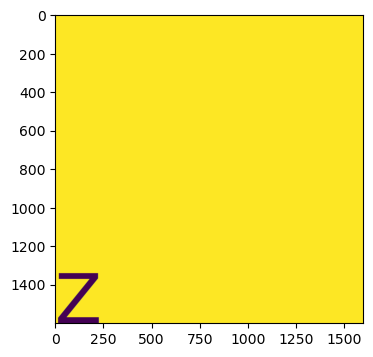

In [2]:
letter = 'Z'
zoom = 4
cmax = 0.1

'''
letter = 'OXO'
zoom = 2
cmax = 1e-8
'''

filename = 'img/' + letter + '.png'

fig = plt.figure(1,figsize = (16,16),dpi=100)
plt.ioff()
ax = fig.add_axes([0.0, 0.0, 1.0, 1.0])
ax.text(0.0,0.0, letter, fontsize=256)
ax.axison = False

fig.canvas.draw()
data = np.frombuffer(fig.canvas.buffer_rgba(), dtype = np.uint8)
data = data.reshape(fig.canvas.get_width_height()[::-1] + (4,))
bw = np.mean(data[:,:,:3],-1)/255.0
bw -=1

plt.clf()
plt.ion()
fig, ax = plt.subplots(1,1,figsize = (4,4),dpi=100)
ax.imshow(bw)

The Fraunhofer diffraction pattern can be written in terms of a 2D Fourier transform, so it is easy to simulate in python using the `numpy.fft` module.

The 2D input array is subjected to a 2D FFT. We zoom in on the centre to see more detail.

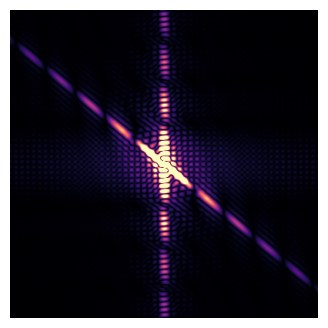

In [3]:
F=fft.fftshift(fft.fft2(bw))
Fr=F.real
Fi=F.imag
F2=Fr*Fr+Fi*Fi
F2 /=np.max(F2)
x_pts, y_pts = np.shape(F2)
F2zoom = F2[int(x_pts/2)-int(x_pts/(2*zoom)):int(x_pts/2)+int(x_pts/(2*zoom)),int(y_pts/2)-int(y_pts/(2*zoom)):int(y_pts/2)+int(y_pts/(2*zoom))]

fig, ax = plt.subplots(1,1,figsize = (4,4),dpi=100)
ax.axison = False
ax.imshow(F2zoom**0.5, clim = [0,cmax],cmap='magma')
plt.show()

In [4]:
fig.savefig(filename, dpi=100, facecolor='white', edgecolor='white')

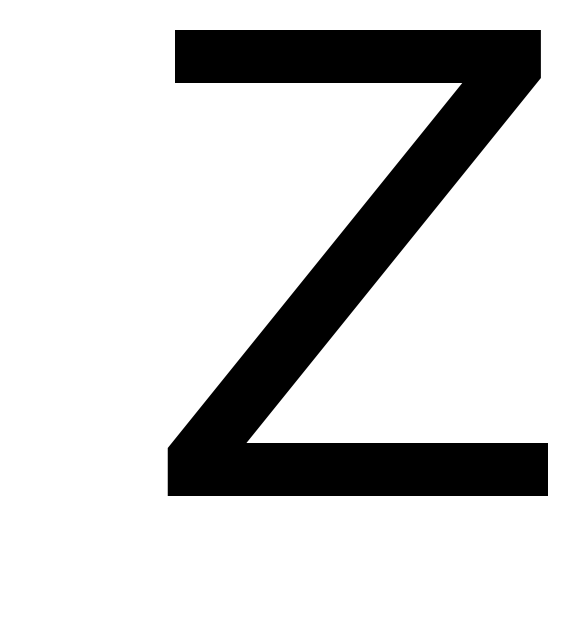

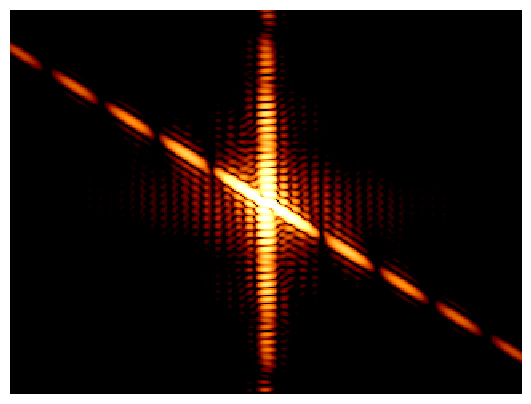

In [5]:
plt.close("all")
fig = plt.figure(1,facecolor='white')
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8]) #add axis for letter
ax.axison = False
ax.text(-0.5,-1.0, 'Z', fontsize=460,family='sans-serif') #print letter
ax.set_xlim(-1.0,1.0)
ax.set_ylim(-1.0,1.0)

fig.canvas.draw() #extract data from figure
data = np.frombuffer(fig.canvas.buffer_rgba(), dtype=np.uint8)
data = data.reshape(fig.canvas.get_width_height()[::-1] + (4,))
bw=np.mean(data[:,:,:3],-1)/255.0

bw-=1.0 #invert
[xpix, ypix]=np.shape(bw)
mul=4 # add zeros to increase resolution
num_x=mul*xpix
num_y=mul*ypix

H=np.zeros((num_x,num_y))
H[int((num_x-xpix)/2):int((num_x+xpix)/2),int((num_y-ypix)/2):int((num_y+ypix)/2)]+=bw

F=np.flipud(fft.fftshift(fft.fft2(H))) #perform Fourier transform and centre
Fr=F.real
Fi=F.imag
F2=Fr*Fr+Fi*Fi #calculate modulus squared
Fs=F2[int((num_x-xpix/2)/2):int((num_x+xpix/2)/2),int((num_y-ypix/2)/2):int((num_y+ypix/2)/2)]

fig = plt.figure(2,facecolor='white')
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.axison = False
p=plt.pcolormesh(np.log(Fs),cmap=mpl.cm.afmhot) # plot log(intensity) pattern
p.set_clim(12,20) #choose limits to highlight desired region
plt.show()

In [6]:
%load_ext version_information

In [7]:
from IPython.core.magic import register_line_magic
from IPython.display import HTML, display

@register_line_magic
def version_info(line=""):
    obj = get_ipython().run_line_magic(
        "version_information", line
    )
    display(HTML(obj._repr_html_()))

In [8]:
%version_info numpy, matplotlib, version_information